# 1. Quantitative Research: S&P 500 Futures (ES) - Multiple Timeframes
## Systematic Trading Approach following TIS Framework

This notebook performs a full Exploratory Data Analysis (AED/EDA) on S&P 500 futures data (ES) from MongoDB, using reusable functions from `eda_utils.py`. We analyze four timeframes: 15min (raw), 1H, 4H, and 1D.

We will:
- Load data from MongoDB using the environment variable `MONGODB_URI_FUTURES_3` and collection `es_15min`.
- Validate data quality by comparing with Yahoo Finance (using `yfinance`).
- Compute returns and log-returns.
- Analyze distribution: mean, volatility (annualized), skewness, excess kurtosis, Jarque-Bera test, tails (days > 3 sigma), extreme events.
- Analyze volatility regimes: rolling volatility, volatility clustering, recent vs historical volatility.
- Analyze autocorrelation: for lags 1, 5, 20, and plot ACF.
- Compute Hurst exponent to assess mean-reversion vs trending behavior.
- Analyze seasonality (by day of week, month, hour) if date index is available.
- Identify extreme events (largest up/down moves) and their frequency.
- Provide a summary for each timeframe, suggesting which strategy family fits best (mean reversion, momentum, event-driven, etc.).

# 1. Imports and configuration

In [10]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')


utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)

from eda_utils import (
    load_data_from_mongo,
    resample_timeframes,
    analyze_timeframe_detailed,
    compute_hurst,
    compute_acf
)

print("Imports and configuration complete.")
print(f"Loaded eda_utils from: {utils_path}")

Imports and configuration complete.
Loaded eda_utils from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils


# 2. Load Data from MongoDB using the reusable loader

In [11]:
df_raw = load_data_from_mongo('es_15min')

print(f"Raw data shape: {df_raw.shape}")
print(f"Date range: {df_raw.index.min()} → {df_raw.index.max()}")
df_raw.head()

Raw data shape: (397203, 5)
Date range: 2009-09-27 18:00:00 → 2026-08-14 16:45:00


,open,high,low,close,volume
time,,,,,
2009-09-27 18:00:00,1042.25,1044.75,1042.25,1043.75,4905
2009-09-27 18:15:00,1043.75,1044.00,1043.50,1043.75,631
2009-09-27 18:30:00,1043.75,1044.00,1043.50,1043.50,177
2009-09-27 18:45:00,1043.75,1043.75,1043.50,1043.75,180
2009-09-27 19:00:00,1043.75,1043.75,1040.25,1041.50,3017


# 3. Data Quality Check: Compare with Yahoo Finance (Daily)

Comparison with Yahoo Finance (daily closes):
       Mongo_close  Yahoo_close     diff_pct
count  4246.000000  4246.000000  4246.000000
mean   3074.394489  3073.820733    -0.009937
std    1684.208407  1682.105494     0.420801
min    1014.250000  1014.250000    -7.033691
25%    1792.812500  1791.562500    -0.134661
50%    2642.000000  2642.000000     0.000000
75%    4178.500000  4179.875000     0.128448
max    7824.250000  7822.500000     3.165919


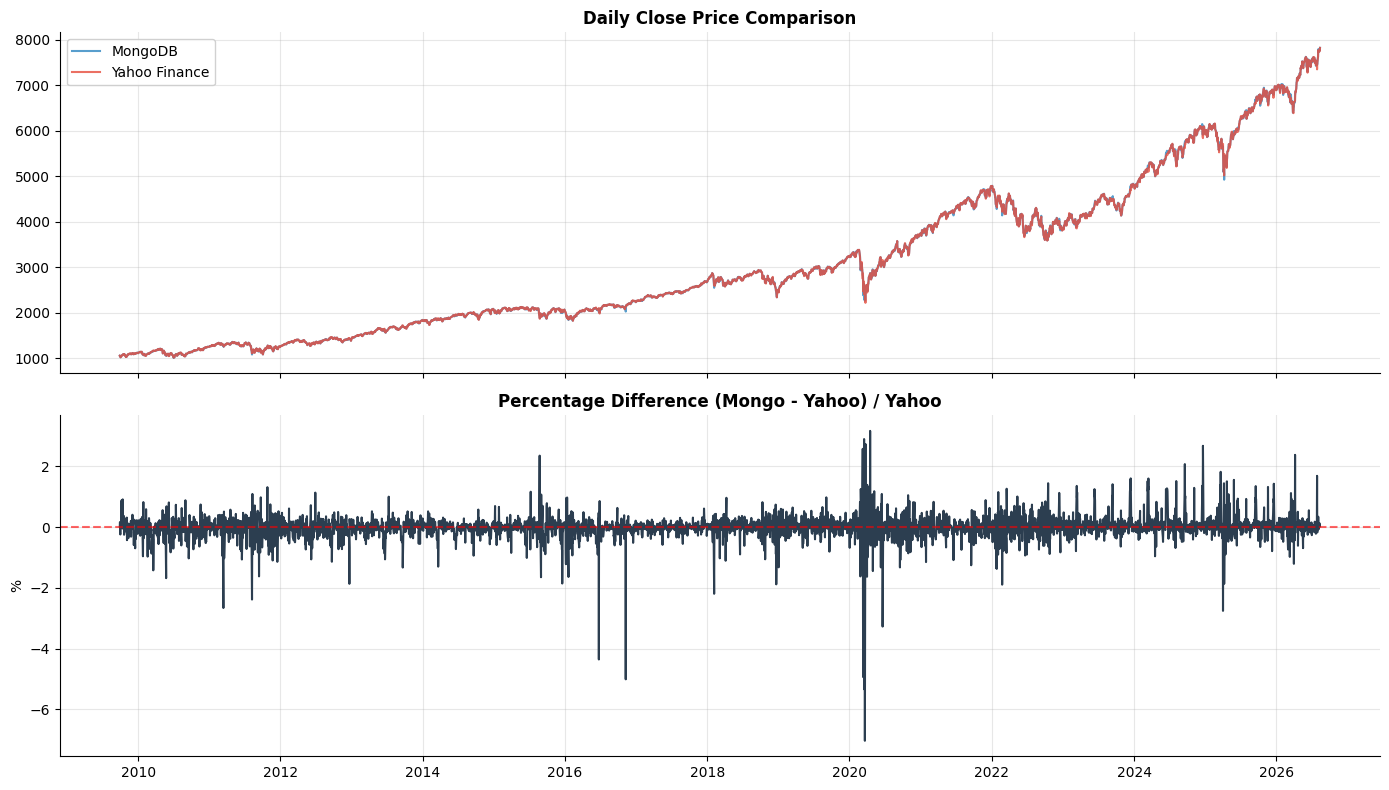

Mean difference: -0.0099%


In [12]:
df_daily = df_raw.resample('D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna()

es_yahoo = yf.download('ES=F', start=df_daily.index.min(), end=df_daily.index.max(), progress=False)
es_yahoo = es_yahoo[['Open', 'High', 'Low', 'Close', 'Volume']]
es_yahoo.columns = ['open', 'high', 'low', 'close', 'volume']

common_idx = df_daily.index.intersection(es_yahoo.index)
df_daily_aligned = df_daily.loc[common_idx]
es_yahoo_aligned = es_yahoo.loc[common_idx]

comparison = pd.DataFrame({
    'Mongo_close': df_daily_aligned['close'],
    'Yahoo_close': es_yahoo_aligned['close']
})
comparison['diff_pct'] = (comparison['Mongo_close'] - comparison['Yahoo_close']) / comparison['Yahoo_close'] * 100

print("Comparison with Yahoo Finance (daily closes):")
print(comparison.describe())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(comparison.index, comparison['Mongo_close'], label='MongoDB', color='#2E86C1', alpha=0.8)
ax1.plot(comparison.index, comparison['Yahoo_close'], label='Yahoo Finance', color='#E74C3C', alpha=0.8)
ax1.set_title('Daily Close Price Comparison', fontweight='bold')
ax1.legend(frameon=True, framealpha=0.9)
ax1.grid(True, alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax2.plot(comparison.index, comparison['diff_pct'], color='#2C3E50', linewidth=1.5)
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.6)
ax2.set_title('Percentage Difference (Mongo - Yahoo) / Yahoo', fontweight='bold')
ax2.set_ylabel('%')
ax2.grid(True, alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

mean_diff = comparison['diff_pct'].mean()
print(f"Mean difference: {mean_diff:.4f}%")

# 4. Resample to Multiple Timeframes using the reusable resampler

In [13]:
timeframes = resample_timeframes(df_raw)

print("Timeframes created:")
for name, df in timeframes.items():
    print(f"{name}: {len(df)}")

Timeframes created:
15min: 397203
1H: 101021
4H: 26970
1D: 5252


# 5. Run Detailed AED on Each Timeframe


ANALYZING 15MIN TIMEFRAME

COMPLETE ANALYSIS: 15min
Bars: 397203
Period: 2009-09-27 18:00:00 → 2026-08-14 16:45:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.50
BULLISH
~12.7%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.00%
Annualized volatility: 15.4%
Skewness: -0.22 (left tail)
Excess Kurtosis: 83.69 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 6831 (1.7%)


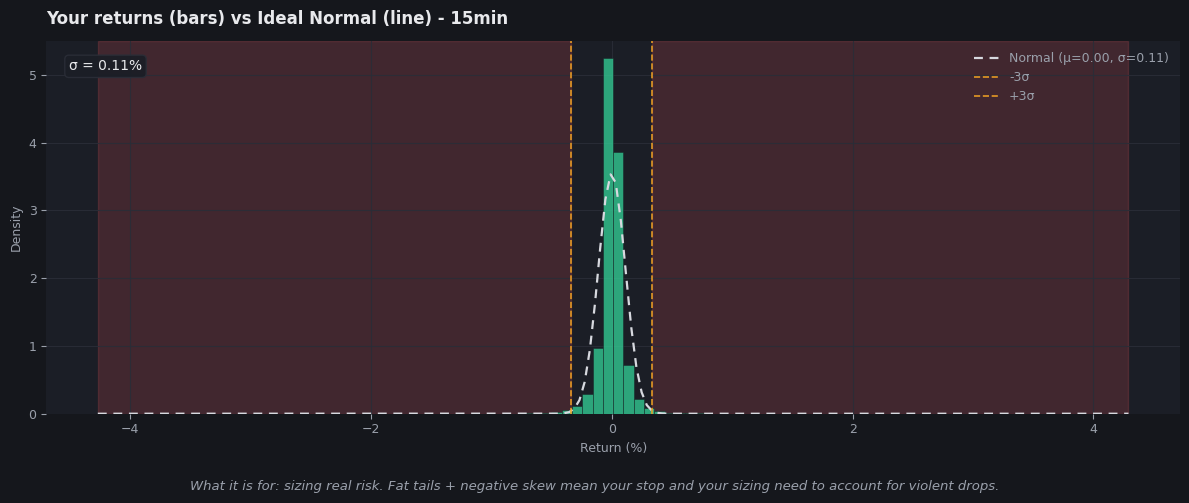


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.31x
Recent volatility (daily): 0.03%
Historical volatility (daily): 0.11%
Comes in waves? low


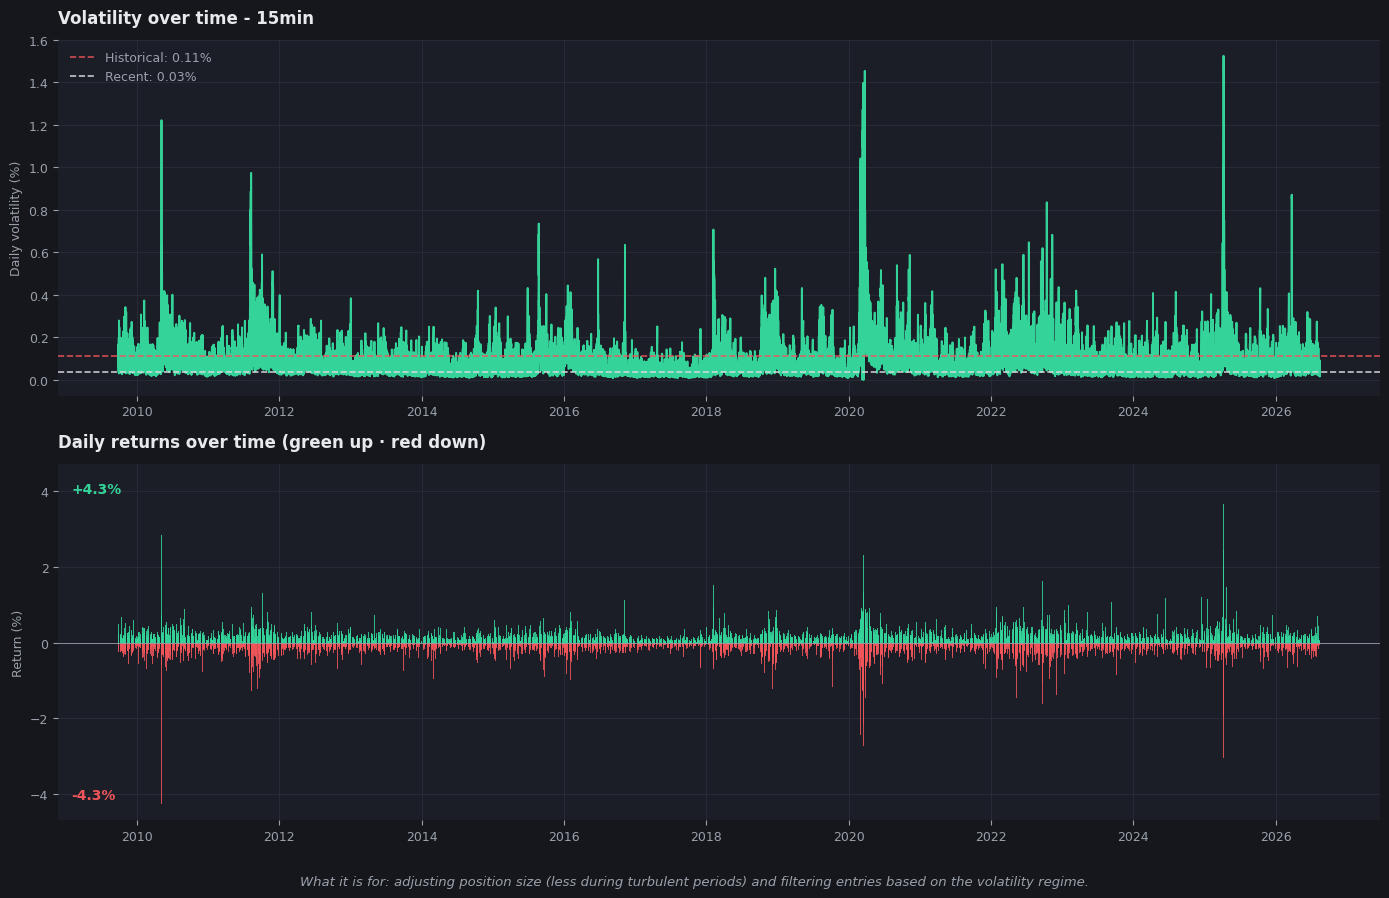


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: -0.01 reverts


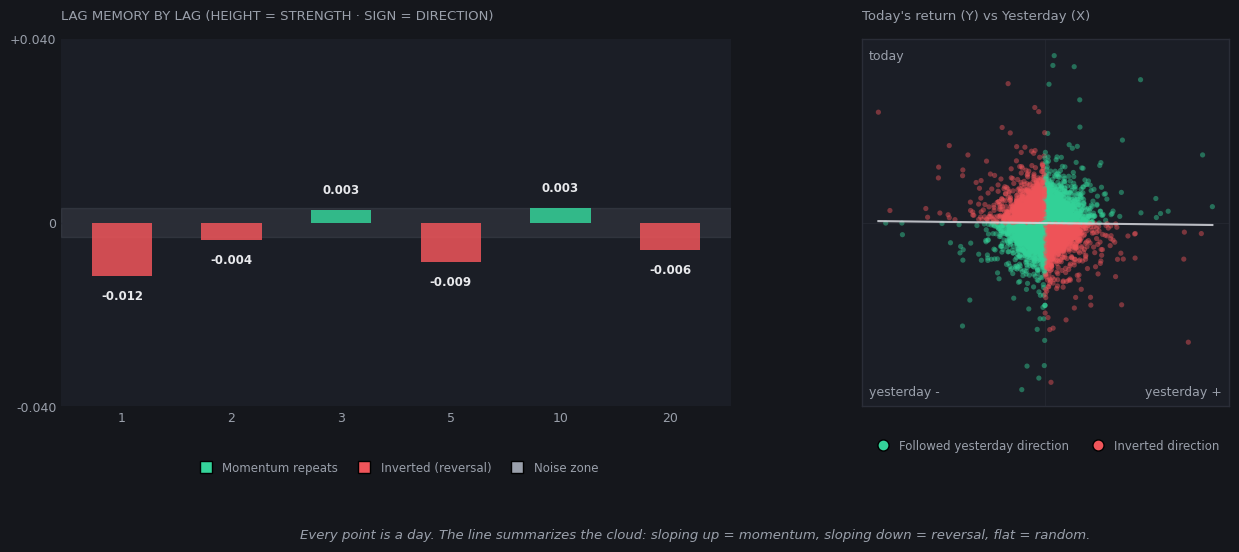


PATTERNS
SEASONALITY?


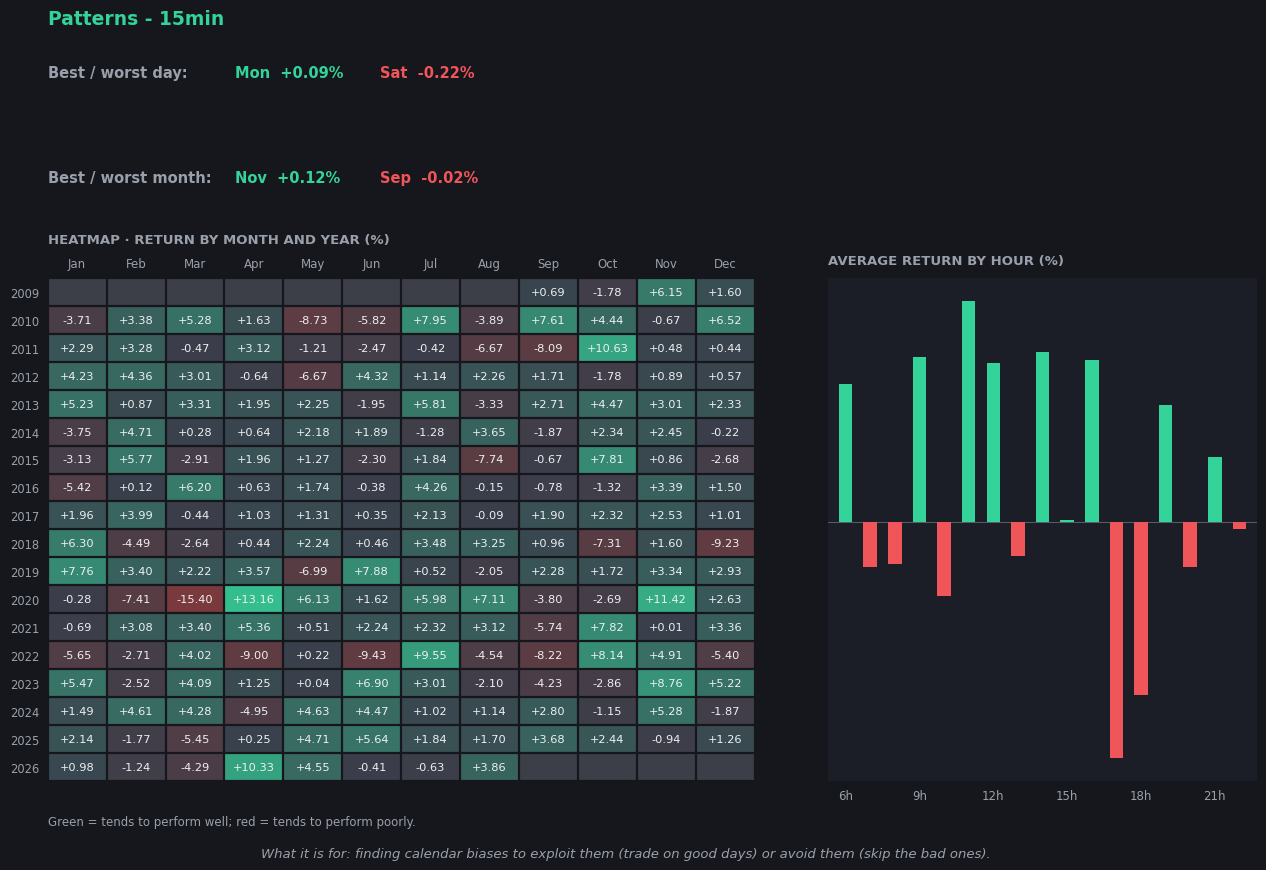


Average return by day of week (Mon-Fri, %):
Mon: 0.09%
Tue: 0.06%
Wed: 0.05%
Thu: 0.02%
Fri: 0.03%

Average return by month (%):
Jan: 0.03%
Feb: 0.04%
Mar: 0.01%
Apr: 0.07%
May: 0.02%
Jun: 0.03%
Jul: 0.11%
Aug: -0.01%
Sep: -0.02%
Oct: 0.07%
Nov: 0.12%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
06:00: 0.00%
07:00: -0.00%
08:00: -0.00%
09:00: 0.00%
10:00: -0.00%
11:00: 0.00%
12:00: 0.00%
13:00: -0.00%
14:00: 0.00%
15:00: 0.00%
16:00: 0.00%
17:00: -0.00%
18:00: -0.00%
19:00: 0.00%
20:00: -0.00%
21:00: 0.00%
22:00: -0.00%

EXTREME EVENTS
REACTION?


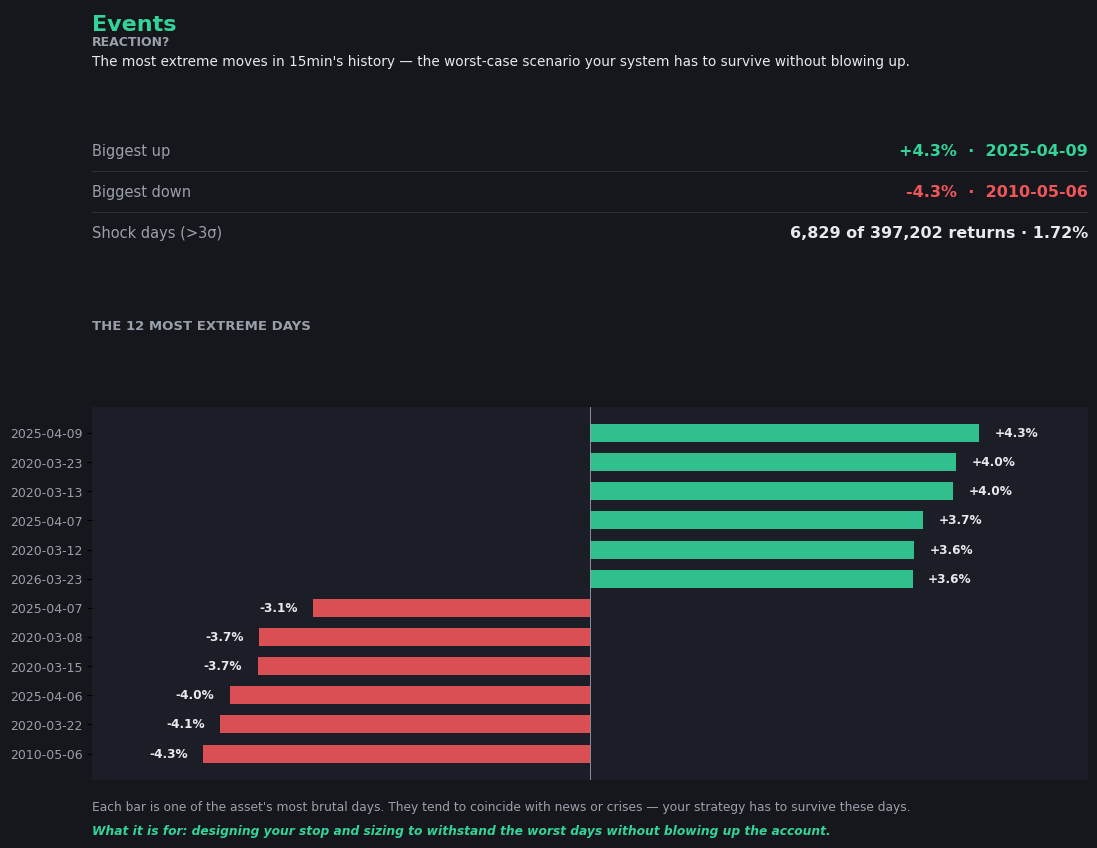

Biggest up: +4.3%
Biggest down: -4.3%
Shock days (>3σ): 6831 of 397,202 returns · 1.72%

Top 12 up days:
+4.3% - 2025-04-09
+4.0% - 2020-03-23
+4.0% - 2020-03-13
+3.7% - 2025-04-07
+3.6% - 2020-03-12
+3.6% - 2026-03-23

Top 12 down days:
-4.3% - 2010-05-06
-4.1% - 2020-03-22
-4.0% - 2025-04-06
-3.7% - 2020-03-15
-3.7% - 2020-03-08
-3.1% - 2025-04-07

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


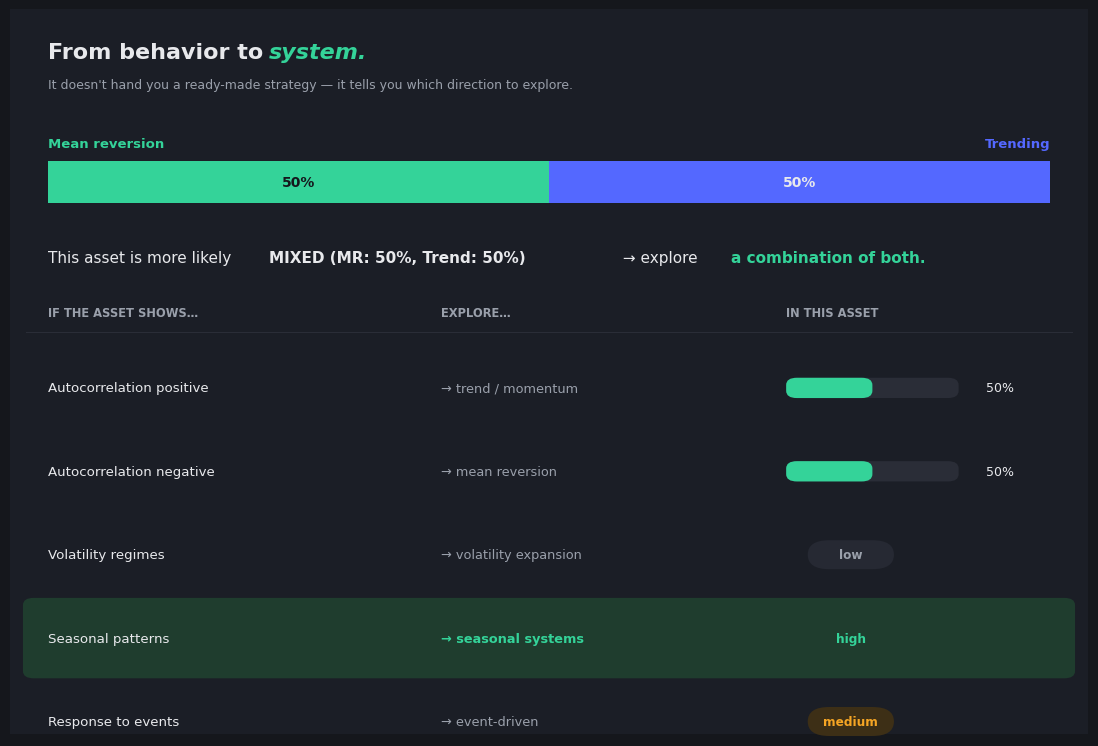


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 15.4%

Skewness
Which side the surprises lean toward. Negative means down moves are more violent than up moves.
→ -0.22 (left tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 83.69 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.012

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.500

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

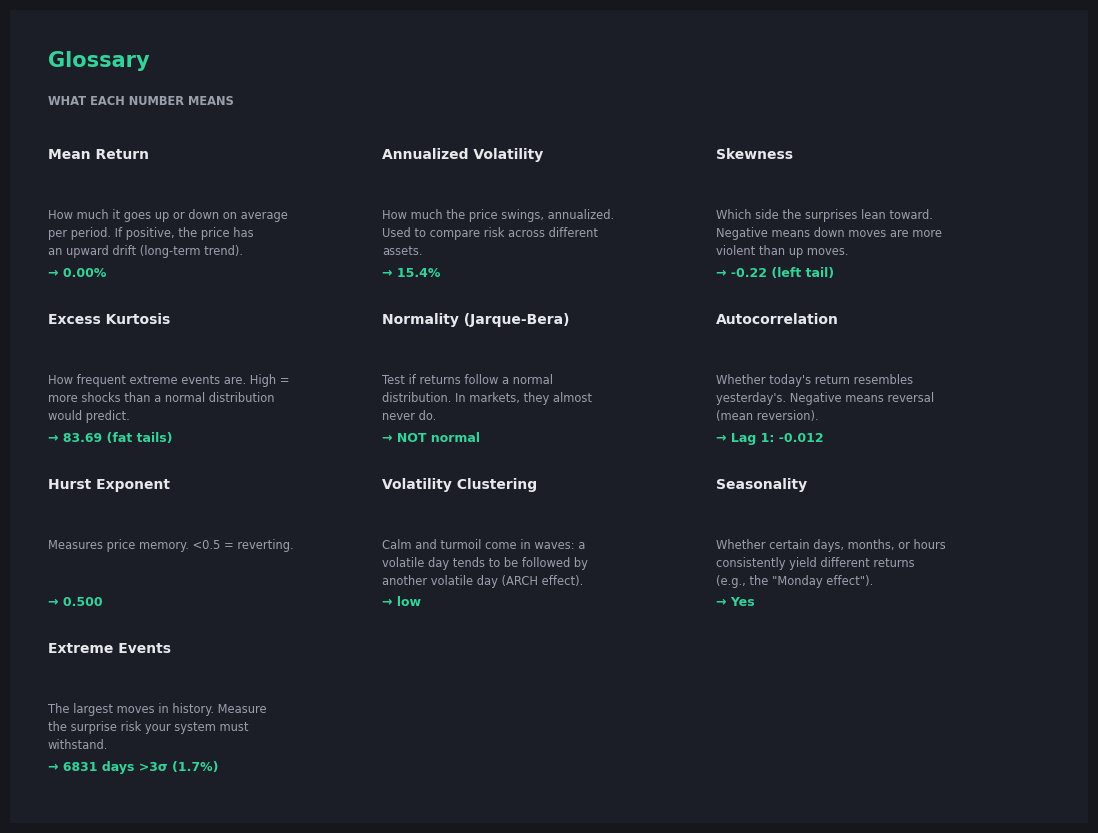




ANALYZING 1H TIMEFRAME

COMPLETE ANALYSIS: 1H
Bars: 101021
Period: 2009-09-27 18:00:00 → 2026-08-14 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.50
BULLISH
~12.7%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.00%
Annualized volatility: 15.4%
Skewness: 0.11 (right tail)
Excess Kurtosis: 49.49 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 1795 (1.8%)


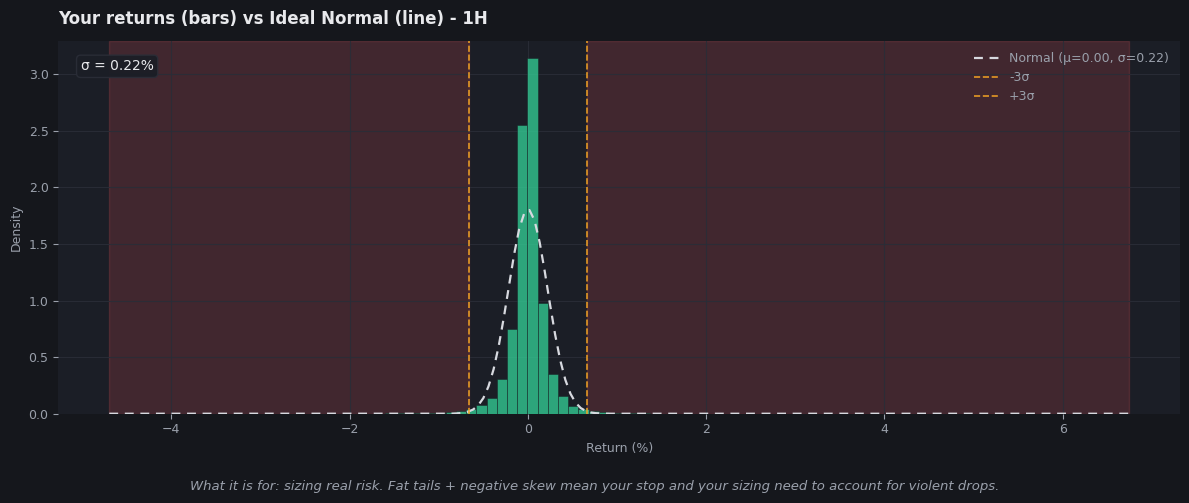


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.26x
Recent volatility (daily): 0.06%
Historical volatility (daily): 0.22%
Comes in waves? low


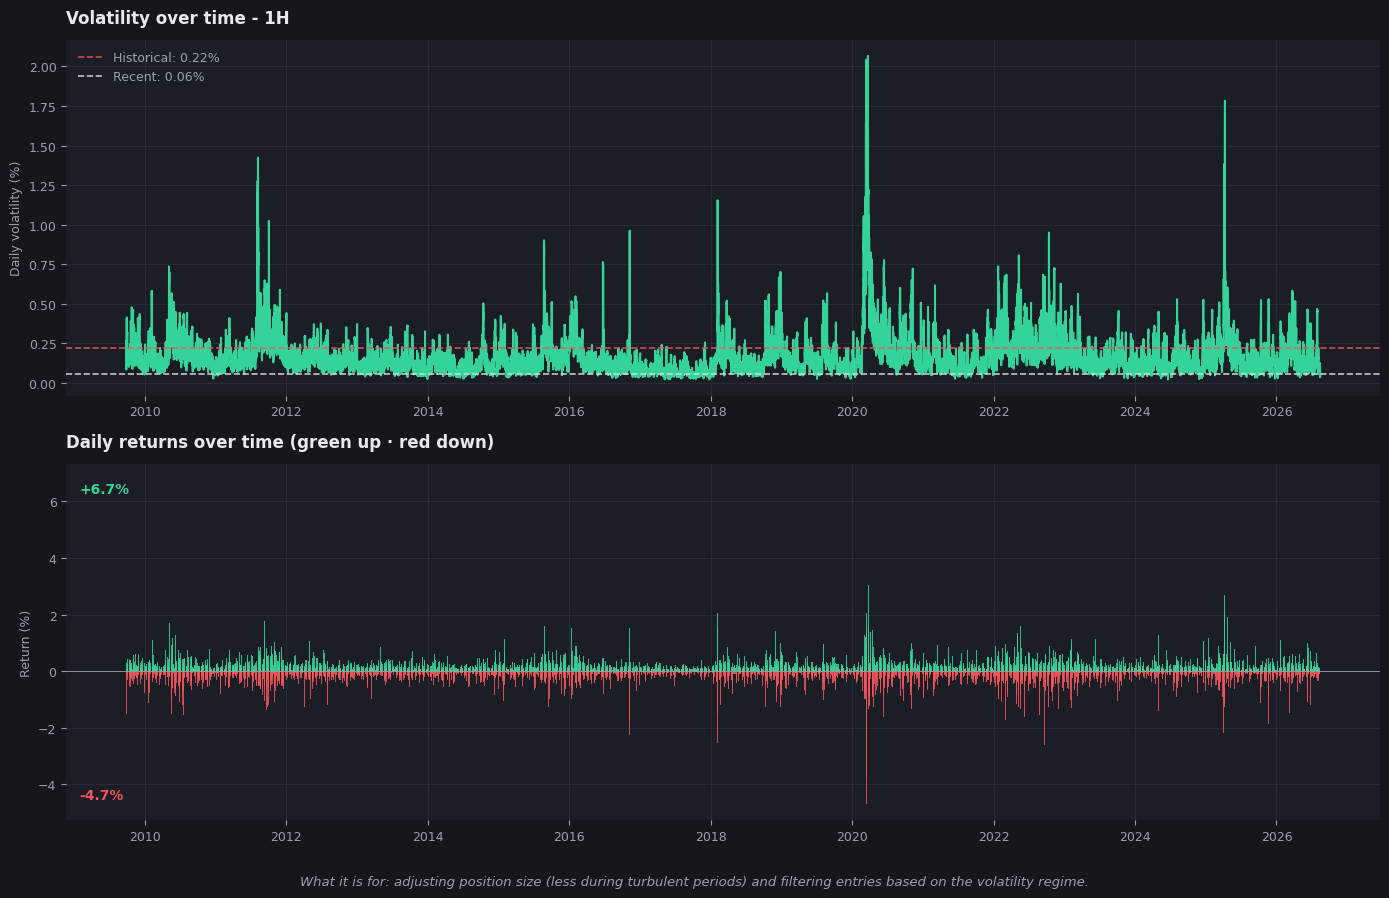


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


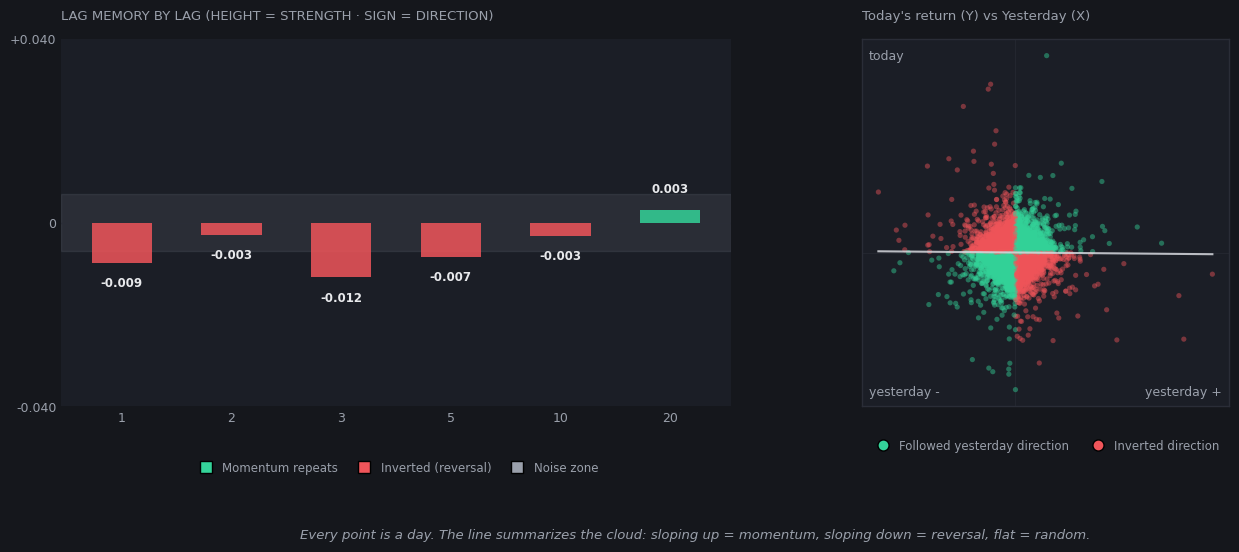


PATTERNS
SEASONALITY?


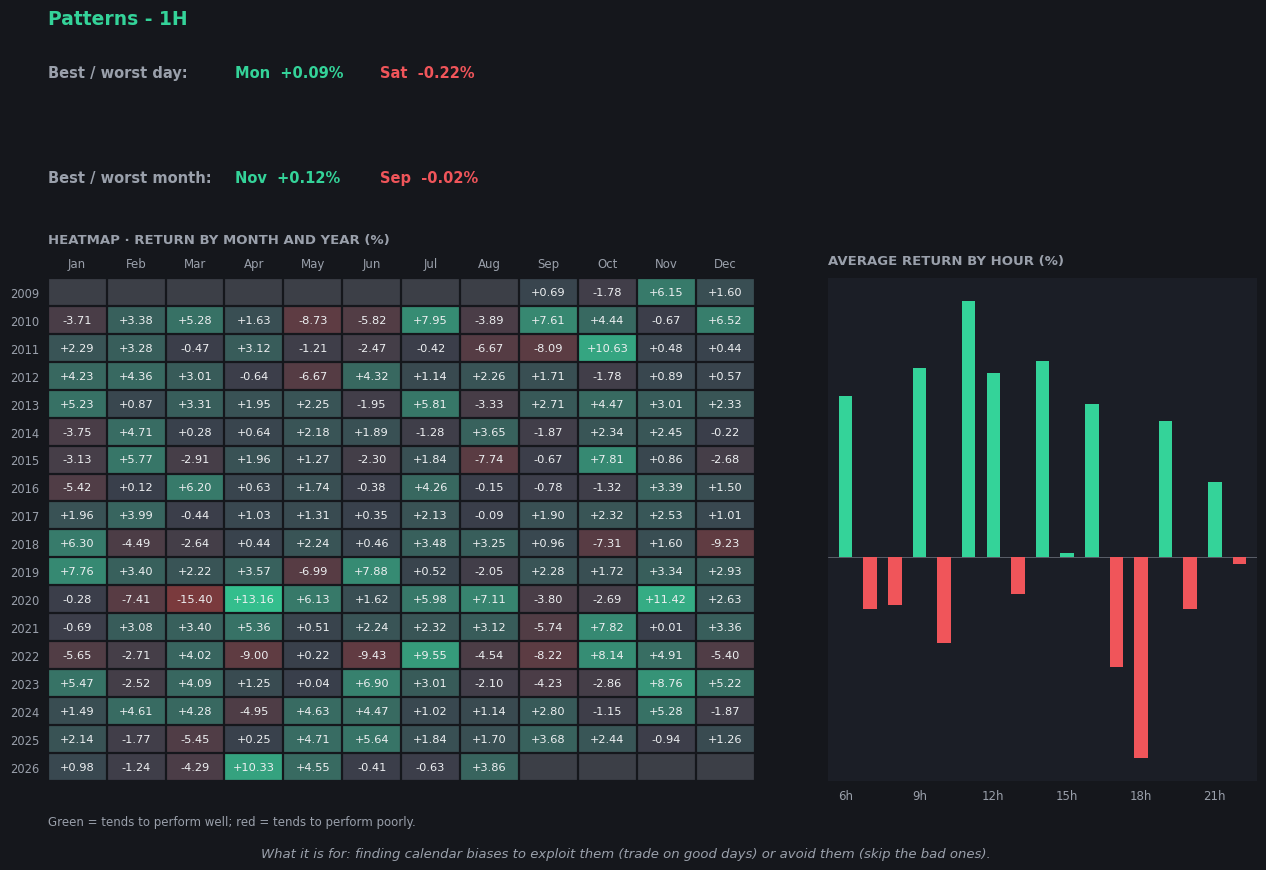


Average return by day of week (Mon-Fri, %):
Mon: 0.09%
Tue: 0.06%
Wed: 0.05%
Thu: 0.02%
Fri: 0.03%

Average return by month (%):
Jan: 0.03%
Feb: 0.04%
Mar: 0.01%
Apr: 0.07%
May: 0.02%
Jun: 0.03%
Jul: 0.11%
Aug: -0.01%
Sep: -0.02%
Oct: 0.07%
Nov: 0.12%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
06:00: 0.00%
07:00: -0.00%
08:00: -0.00%
09:00: 0.01%
10:00: -0.00%
11:00: 0.01%
12:00: 0.01%
13:00: -0.00%
14:00: 0.01%
15:00: 0.00%
16:00: 0.00%
17:00: -0.00%
18:00: -0.01%
19:00: 0.00%
20:00: -0.00%
21:00: 0.00%
22:00: -0.00%

EXTREME EVENTS
REACTION?


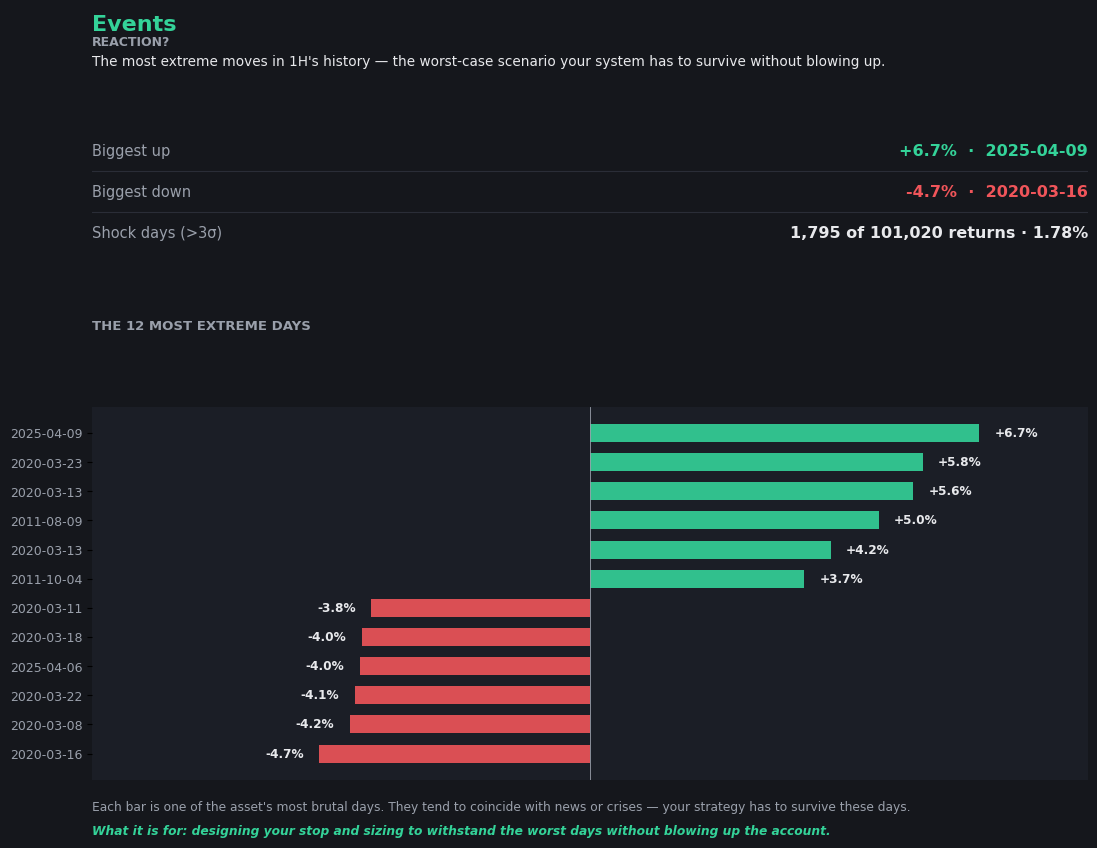

Biggest up: +6.7%
Biggest down: -4.7%
Shock days (>3σ): 1795 of 101,020 returns · 1.78%

Top 12 up days:
+6.7% - 2025-04-09
+5.8% - 2020-03-23
+5.6% - 2020-03-13
+5.0% - 2011-08-09
+4.2% - 2020-03-13
+3.7% - 2011-10-04

Top 12 down days:
-4.7% - 2020-03-16
-4.2% - 2020-03-08
-4.1% - 2020-03-22
-4.0% - 2025-04-06
-4.0% - 2020-03-18
-3.8% - 2020-03-11

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


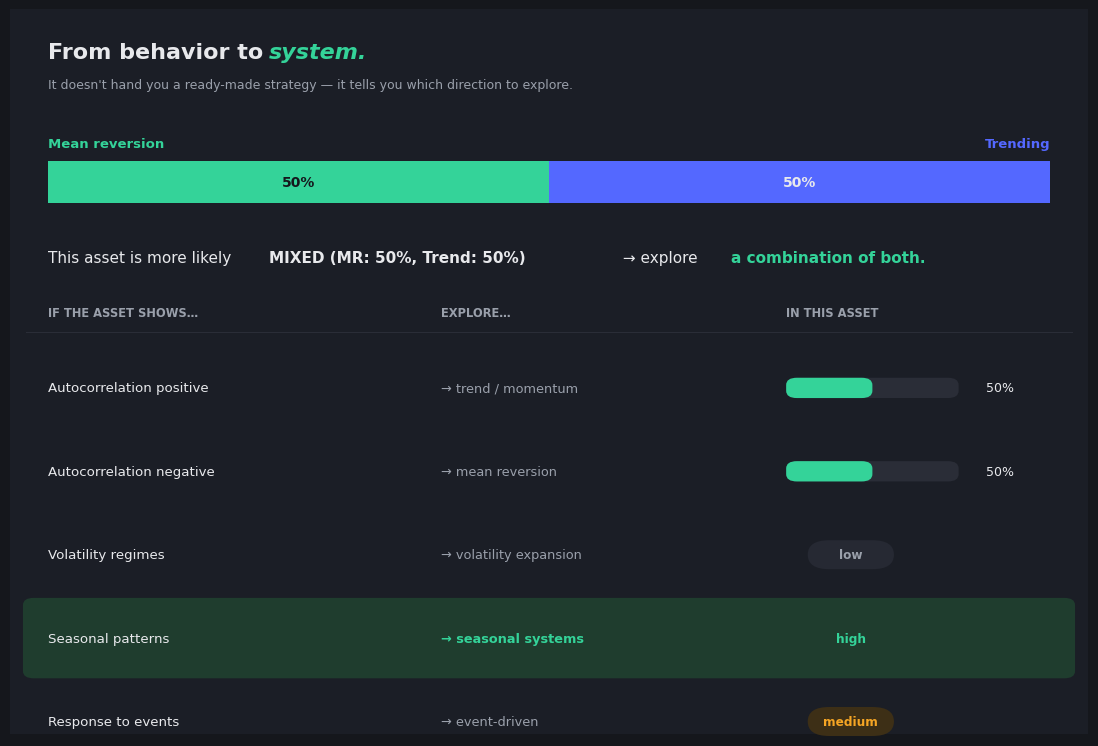


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 15.4%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.11 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 49.49 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.009

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.500

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

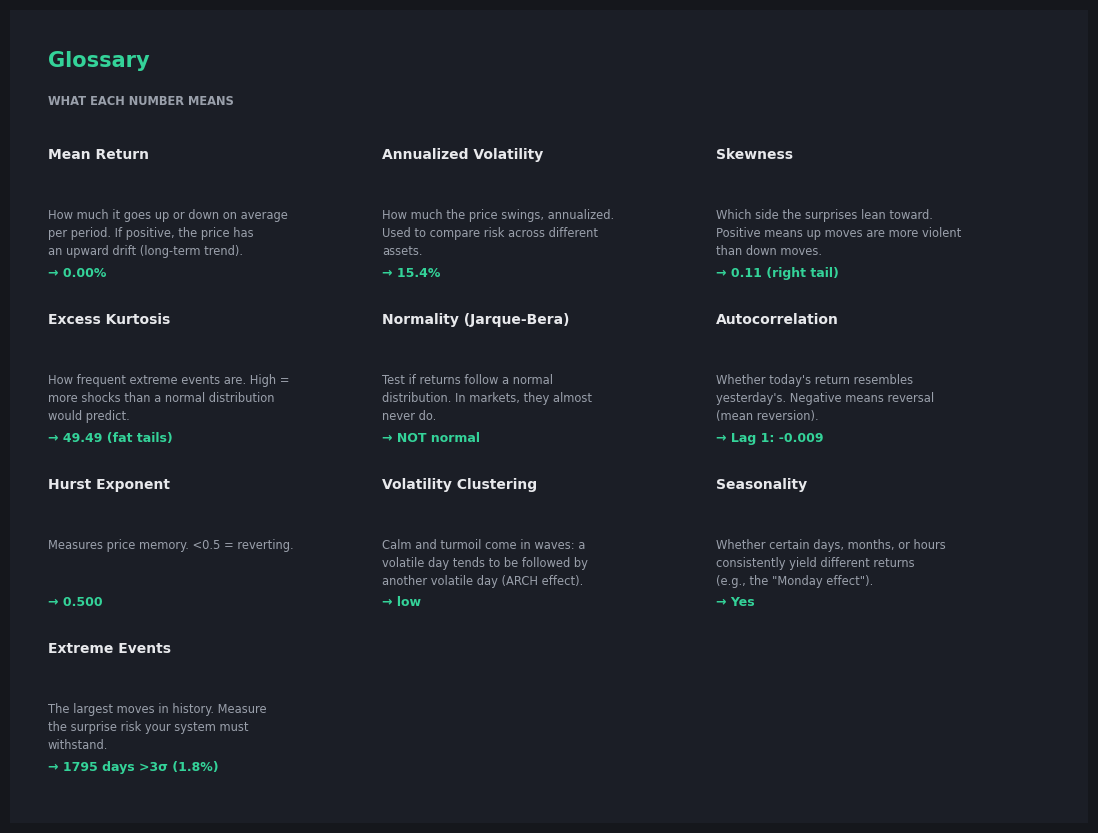




ANALYZING 4H TIMEFRAME

COMPLETE ANALYSIS: 4H
Bars: 26970
Period: 2009-09-27 16:00:00 → 2026-08-14 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.49
BULLISH
~12.7%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.01%
Annualized volatility: 15.4%
Skewness: 0.12 (right tail)
Excess Kurtosis: 33.77 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 471 (1.7%)


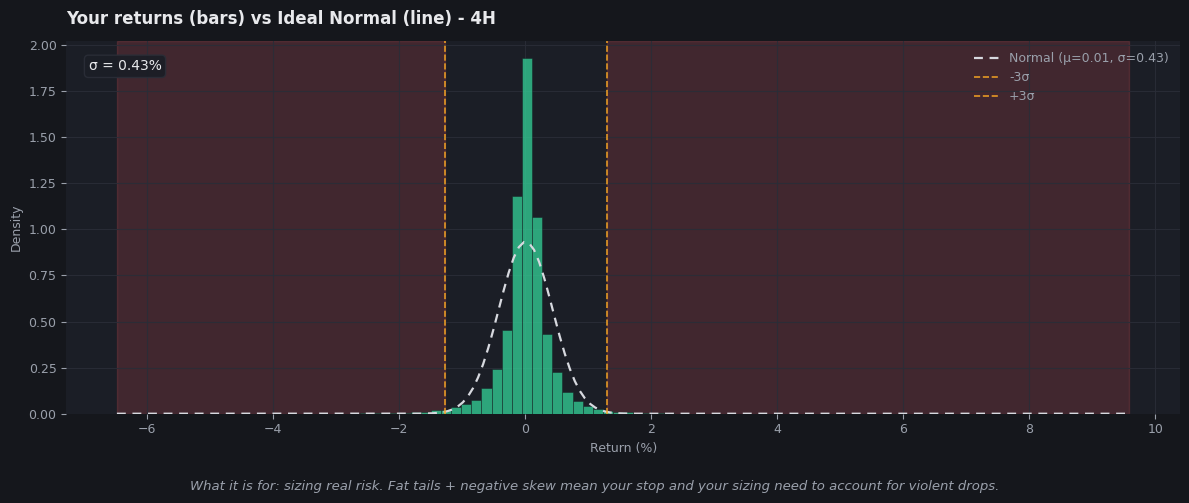


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.31x
Recent volatility (daily): 0.13%
Historical volatility (daily): 0.43%
Comes in waves? low


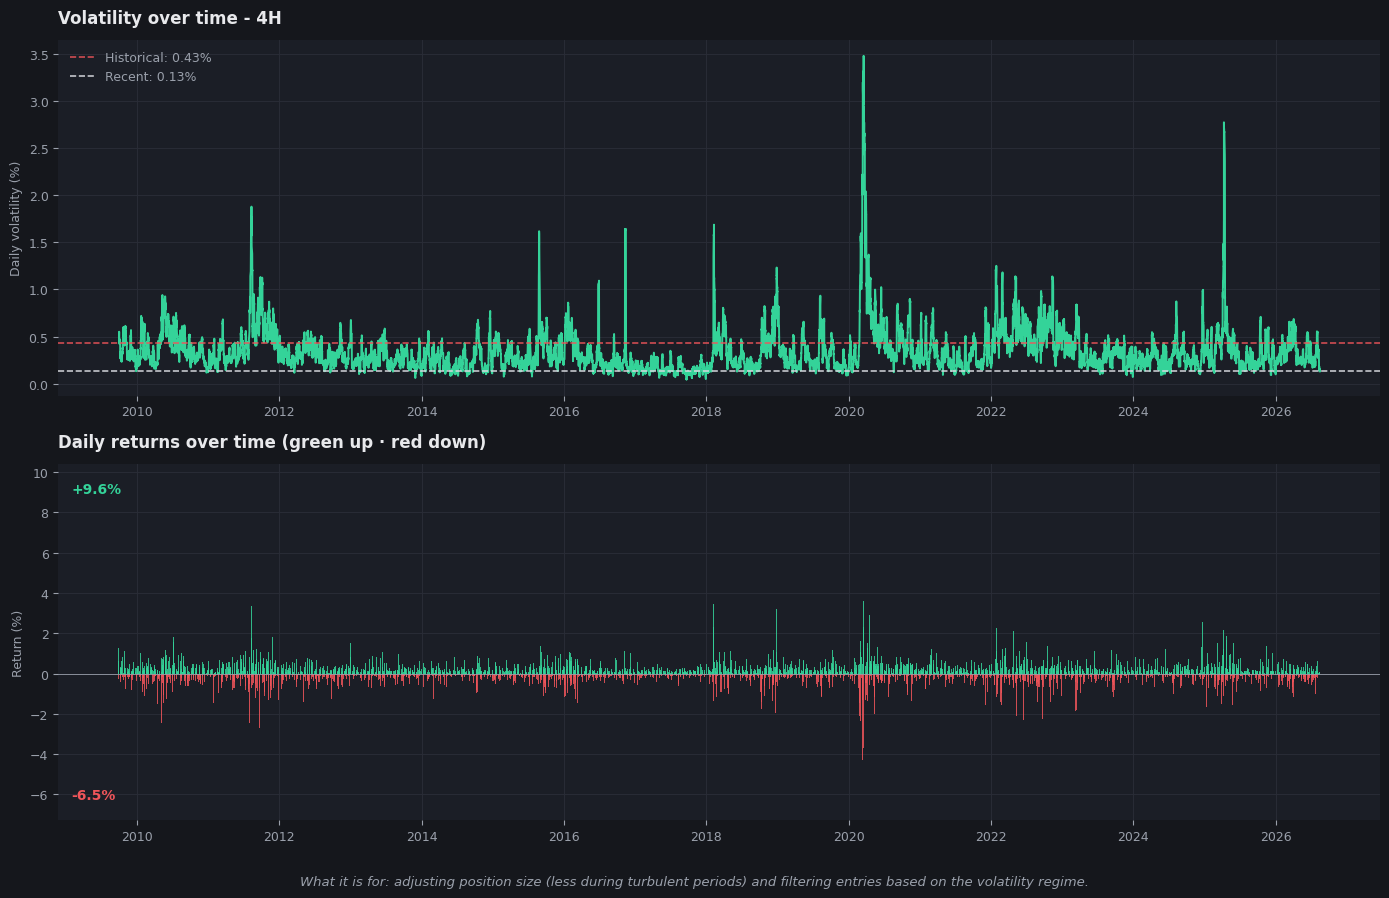


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.01 ~0


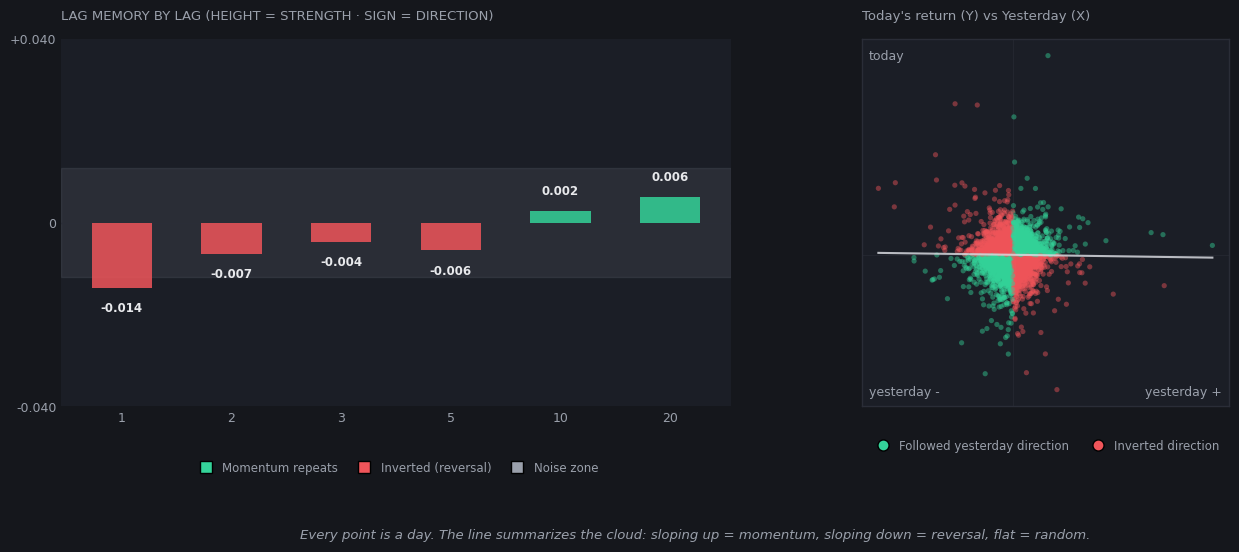


PATTERNS
SEASONALITY?


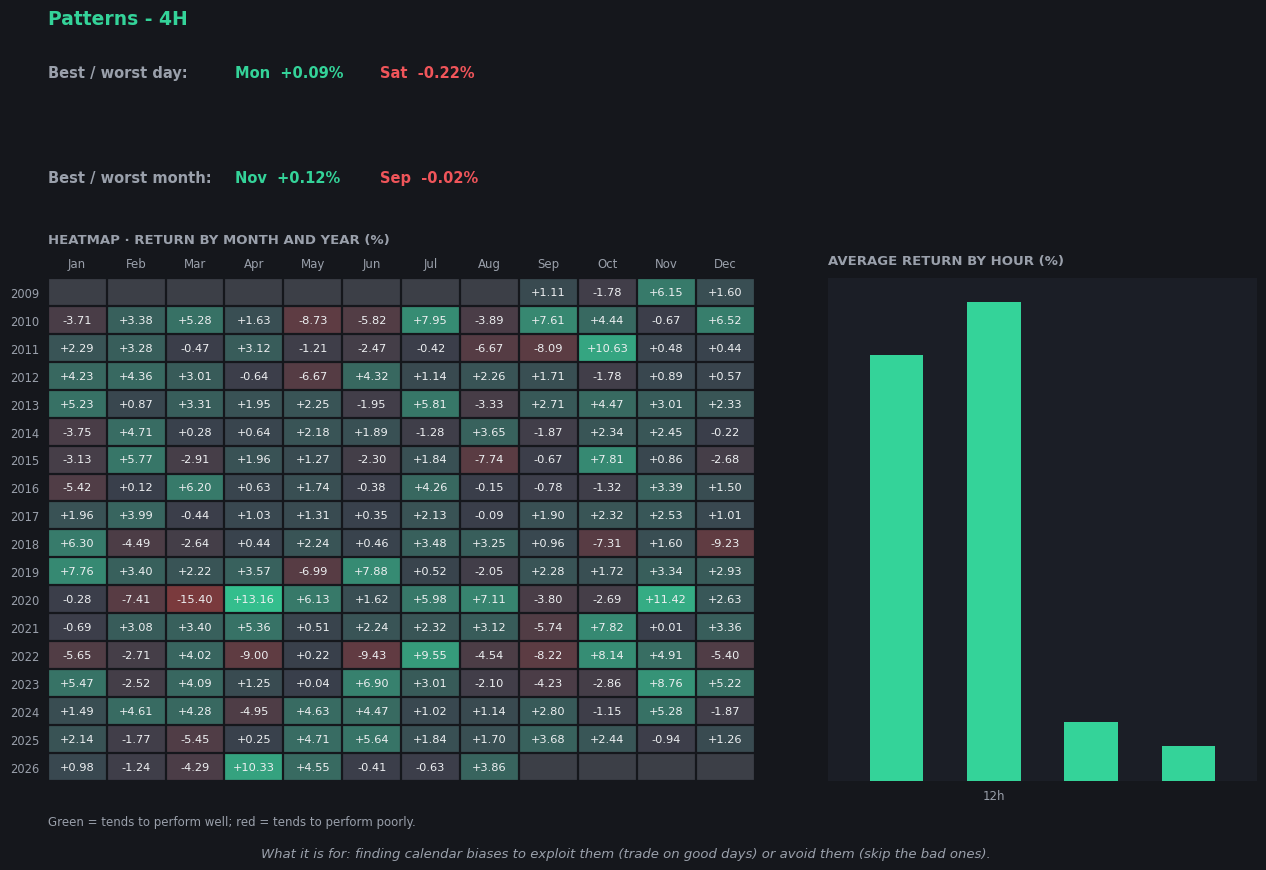


Average return by day of week (Mon-Fri, %):
Mon: 0.09%
Tue: 0.06%
Wed: 0.05%
Thu: 0.02%
Fri: 0.03%

Average return by month (%):
Jan: 0.03%
Feb: 0.04%
Mar: 0.01%
Apr: 0.07%
May: 0.02%
Jun: 0.03%
Jul: 0.11%
Aug: -0.01%
Sep: -0.02%
Oct: 0.07%
Nov: 0.12%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
08:00: 0.01%
12:00: 0.01%
16:00: 0.00%
20:00: 0.00%

EXTREME EVENTS
REACTION?


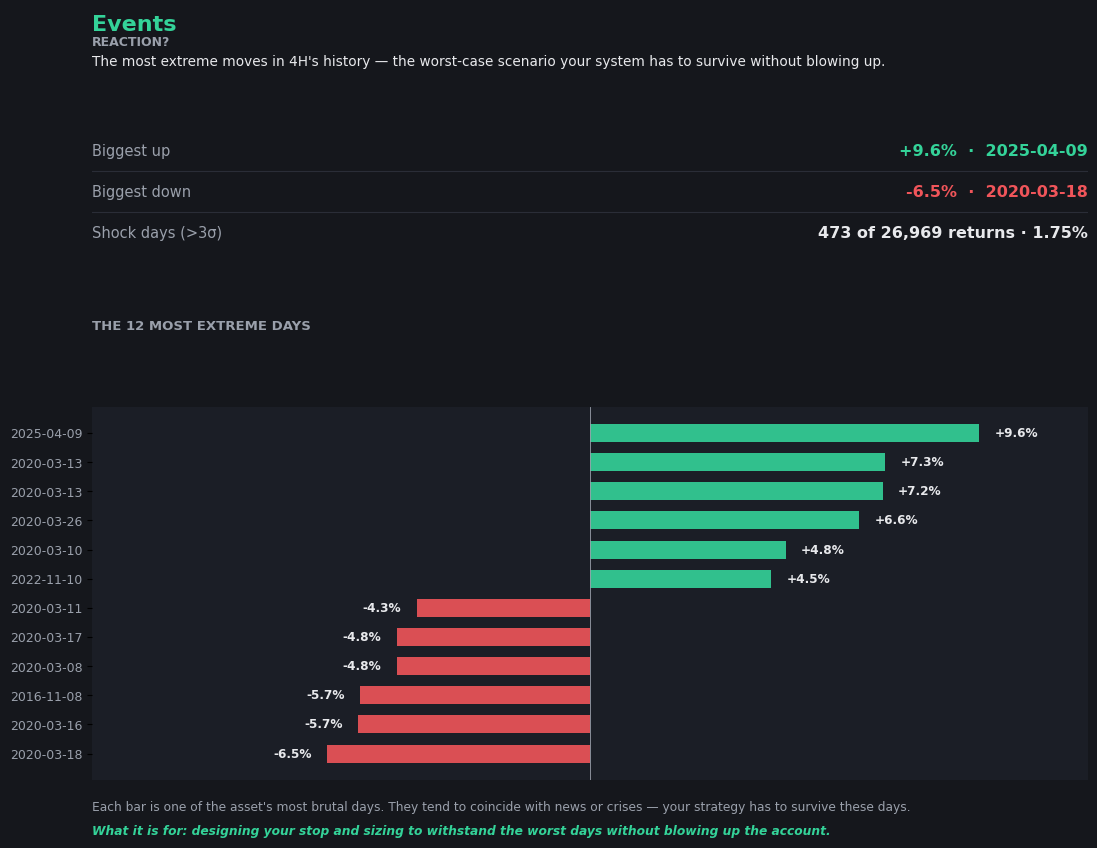

Biggest up: +9.6%
Biggest down: -6.5%
Shock days (>3σ): 471 of 26,969 returns · 1.75%

Top 12 up days:
+9.6% - 2025-04-09
+7.3% - 2020-03-13
+7.2% - 2020-03-13
+6.6% - 2020-03-26
+4.8% - 2020-03-10
+4.5% - 2022-11-10

Top 12 down days:
-6.5% - 2020-03-18
-5.7% - 2020-03-16
-5.7% - 2016-11-08
-4.8% - 2020-03-08
-4.8% - 2020-03-17
-4.3% - 2020-03-11

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


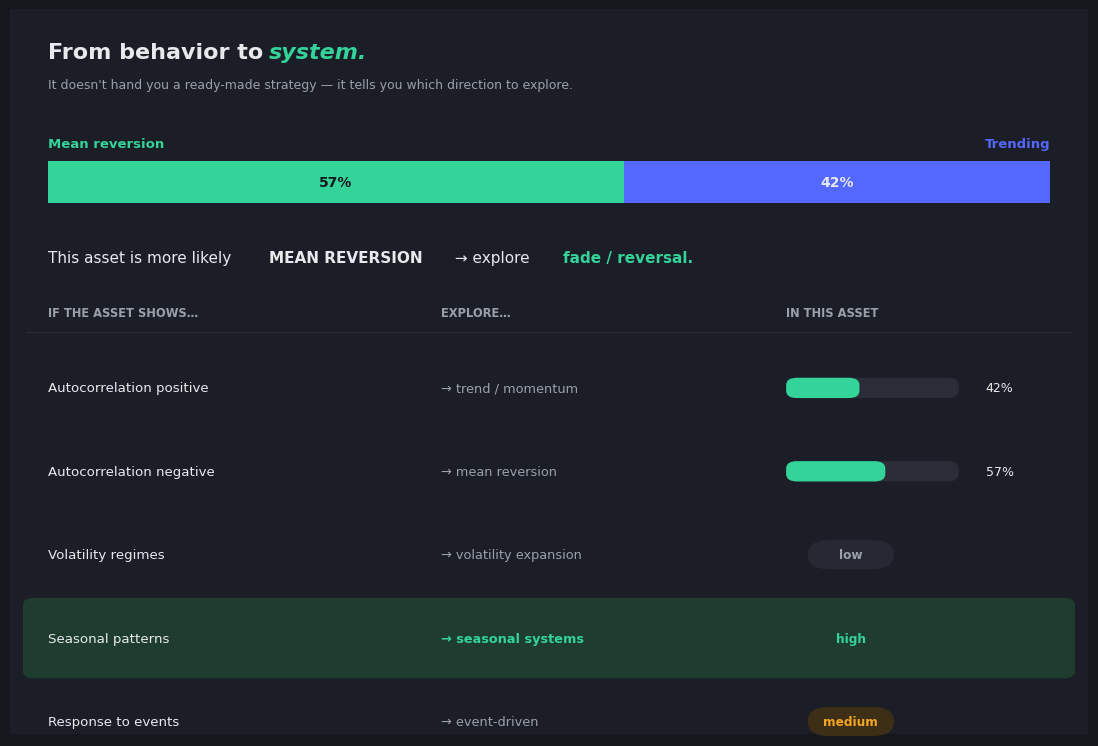


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.01%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 15.4%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.12 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 33.77 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.014

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.486

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

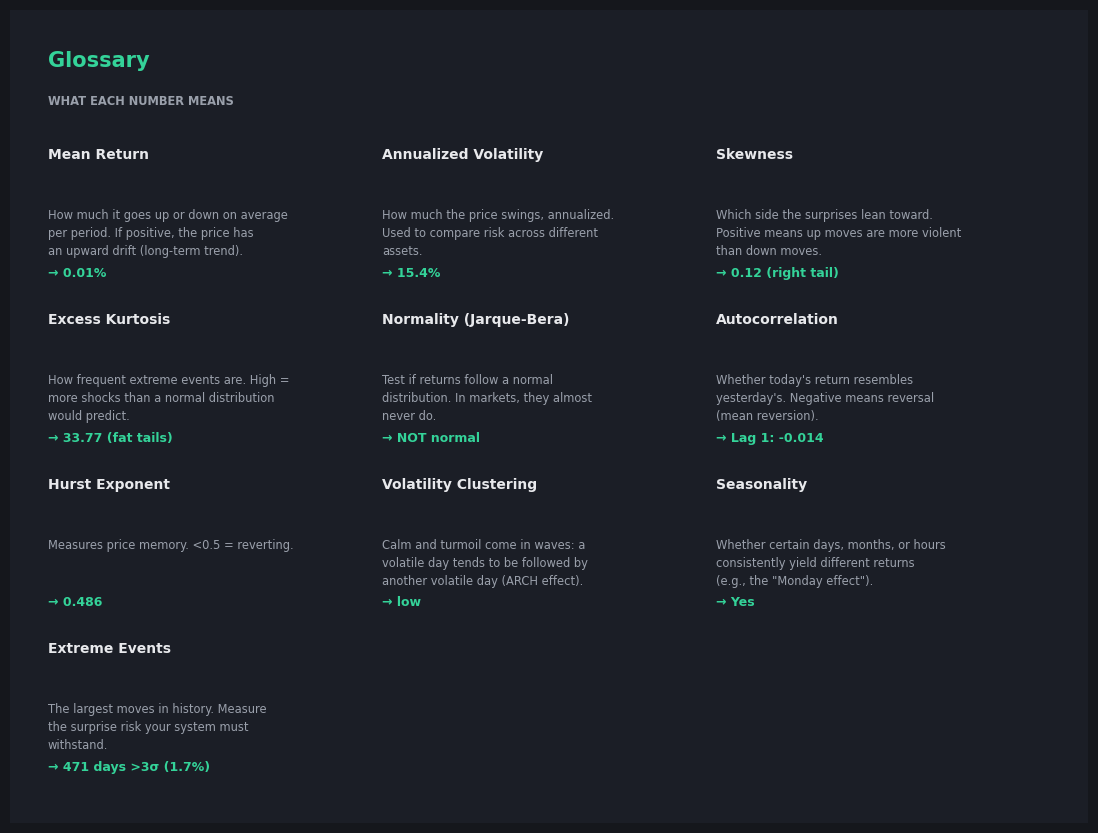




ANALYZING 1D TIMEFRAME

COMPLETE ANALYSIS: 1D
Bars: 5252
Period: 2009-09-27 00:00:00 → 2026-08-14 00:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.47
BULLISH
~12.7%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.04%
Annualized volatility: 15.4%
Skewness: 0.06 (symmetric)
Excess Kurtosis: 13.22 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 76 (1.4%)


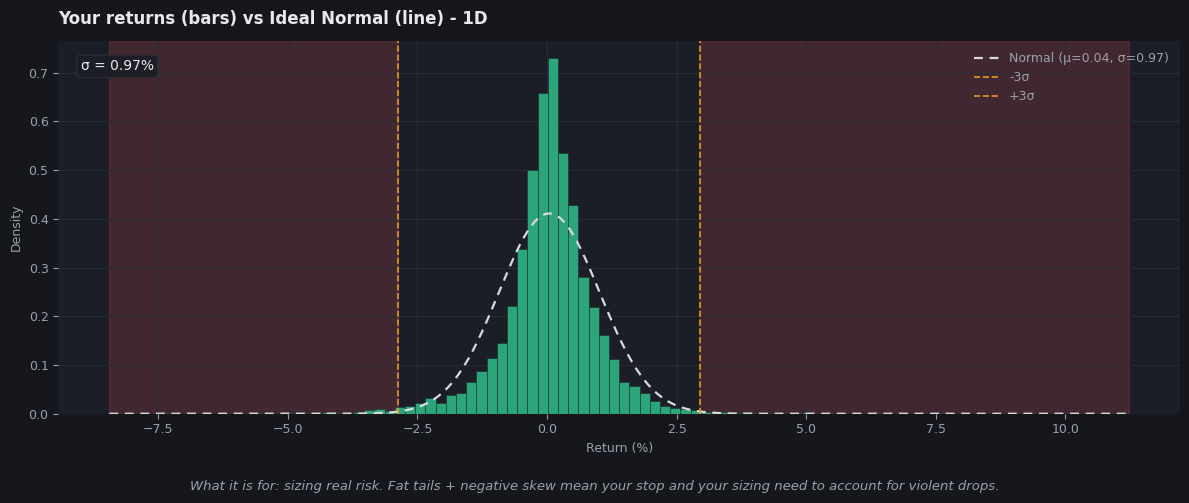


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.66x
Recent volatility (daily): 0.64%
Historical volatility (daily): 0.97%
Comes in waves? strong


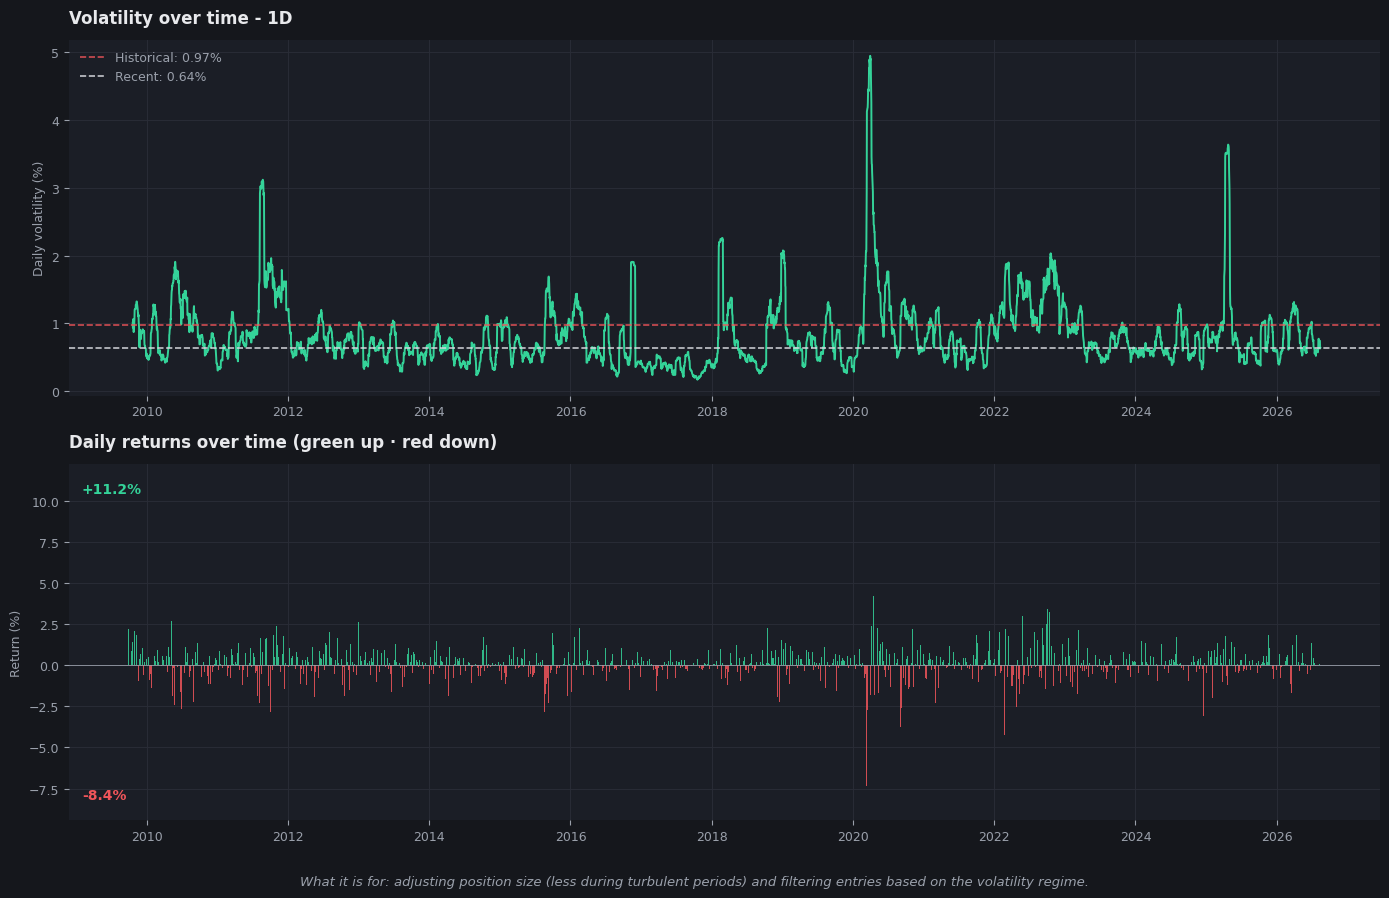


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.07 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


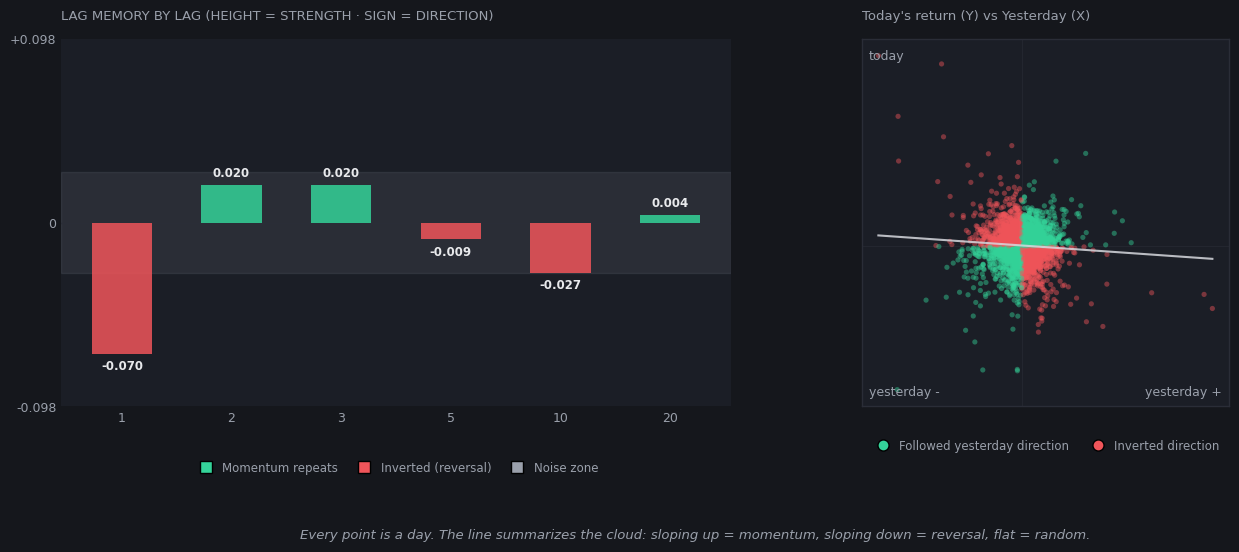


PATTERNS
SEASONALITY?


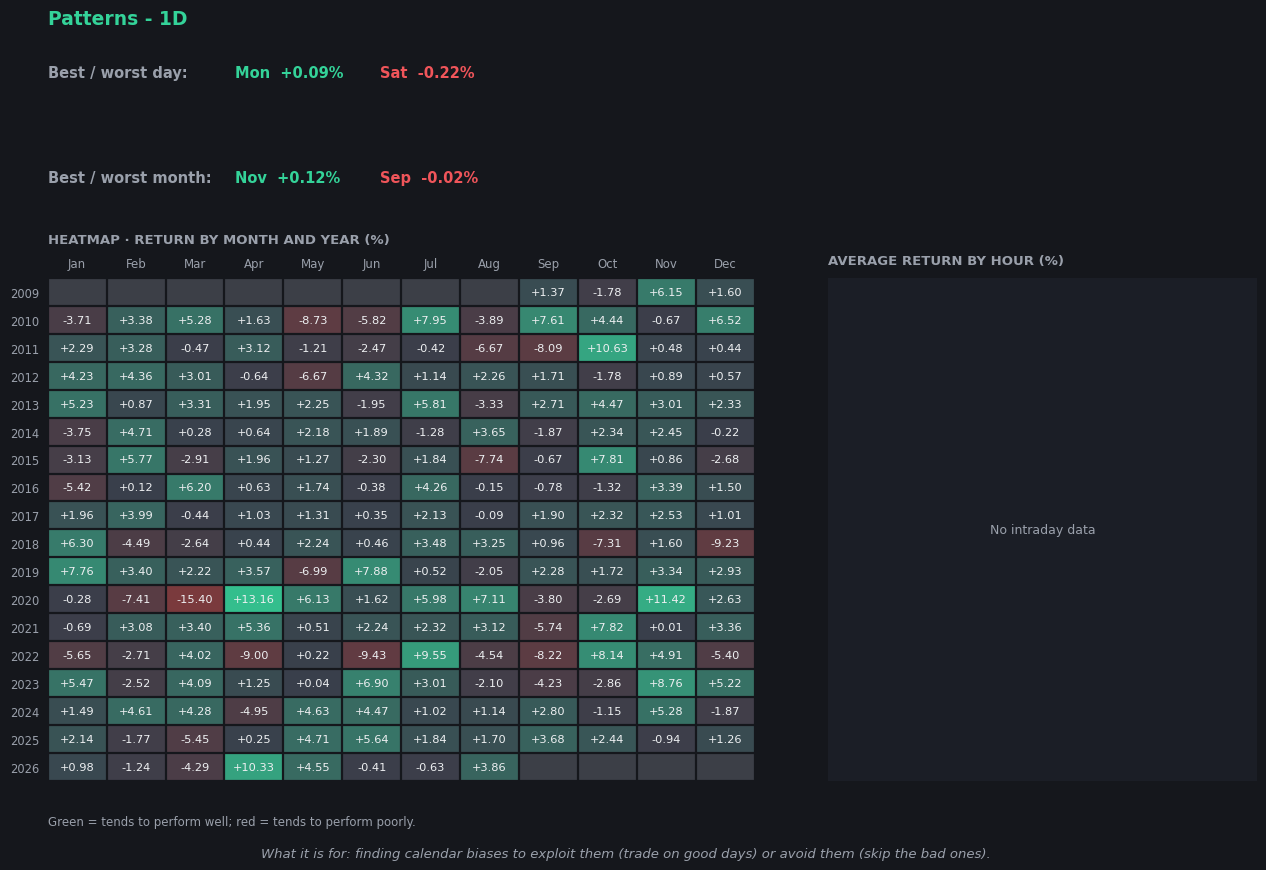


Average return by day of week (Mon-Fri, %):
Mon: 0.09%
Tue: 0.06%
Wed: 0.05%
Thu: 0.02%
Fri: 0.03%

Average return by month (%):
Jan: 0.03%
Feb: 0.04%
Mar: 0.01%
Apr: 0.07%
May: 0.02%
Jun: 0.03%
Jul: 0.11%
Aug: -0.01%
Sep: -0.02%
Oct: 0.07%
Nov: 0.12%
Dec: 0.02%

EXTREME EVENTS
REACTION?


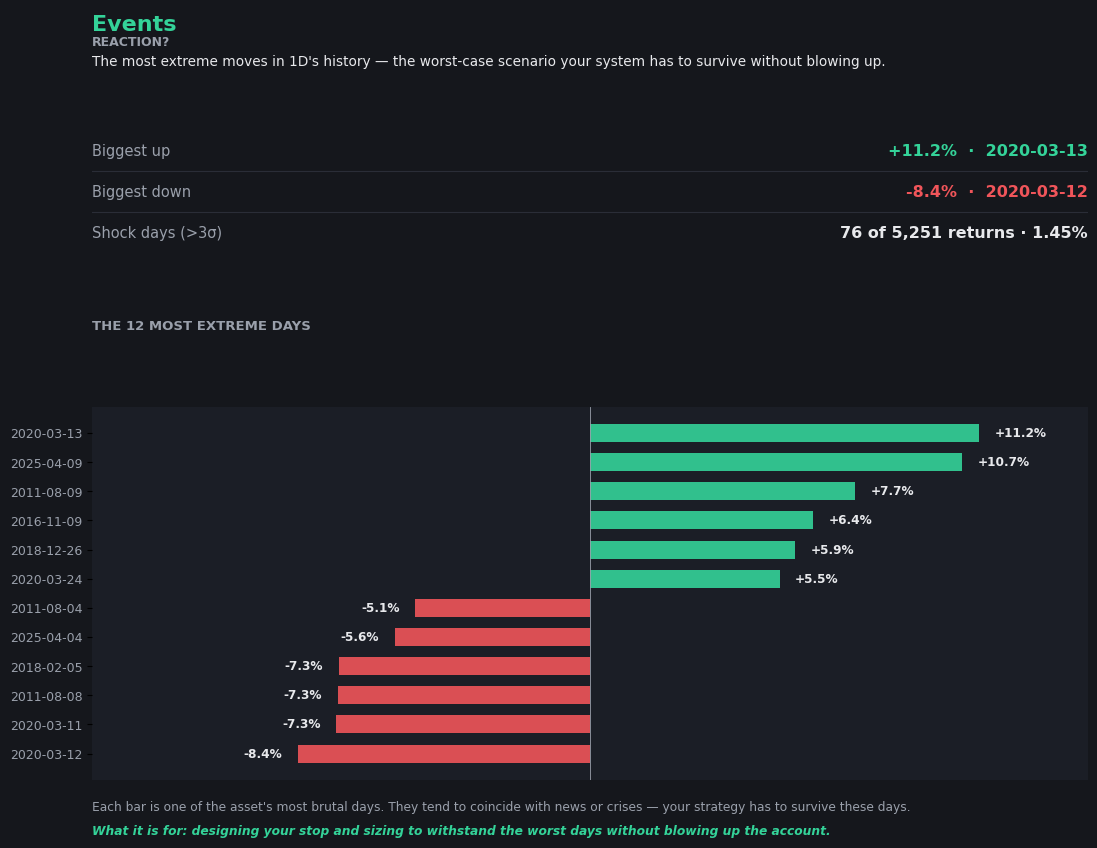

Biggest up: +11.2%
Biggest down: -8.4%
Shock days (>3σ): 76 of 5,251 returns · 1.45%

Top 12 up days:
+11.2% - 2020-03-13
+10.7% - 2025-04-09
+7.7% - 2011-08-09
+6.4% - 2016-11-09
+5.9% - 2018-12-26
+5.5% - 2020-03-24

Top 12 down days:
-8.4% - 2020-03-12
-7.3% - 2020-03-11
-7.3% - 2011-08-08
-7.3% - 2018-02-05
-5.6% - 2025-04-04
-5.1% - 2011-08-04

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation negative	→ mean reversion	57%
Volatility regimes	→ volatility expansion	high
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


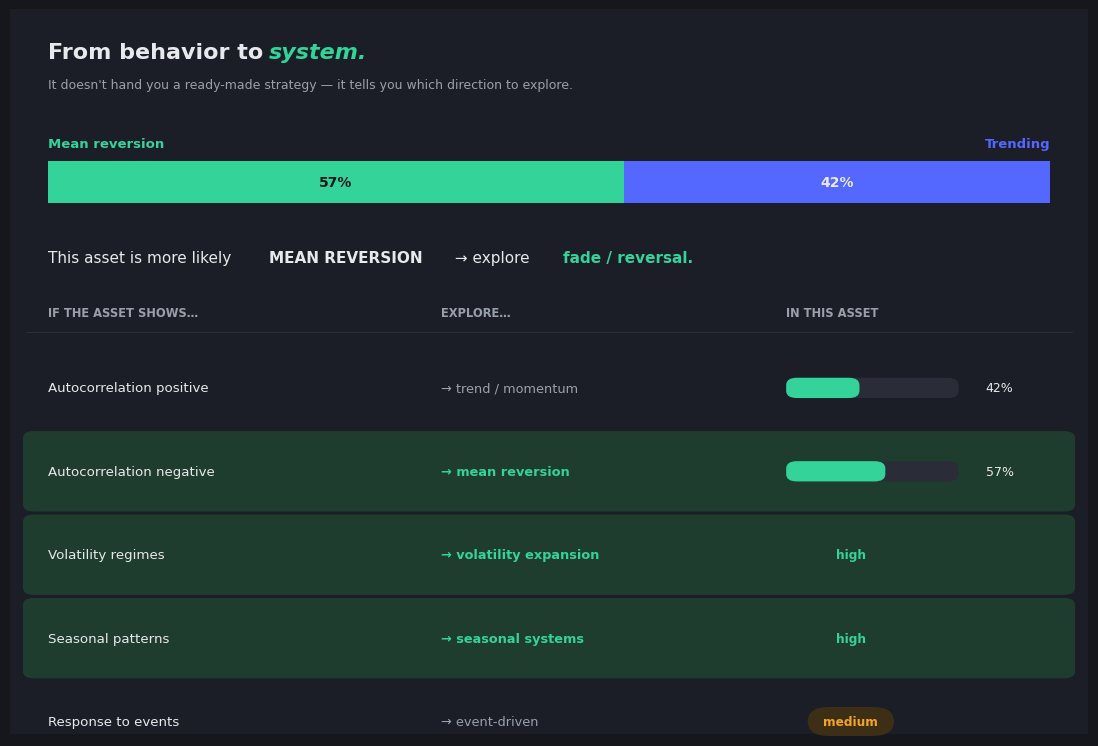


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.04%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 15.4%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.06 (symmetric)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 13.22 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.070

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.471

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ strong

Seasonality
Wheth

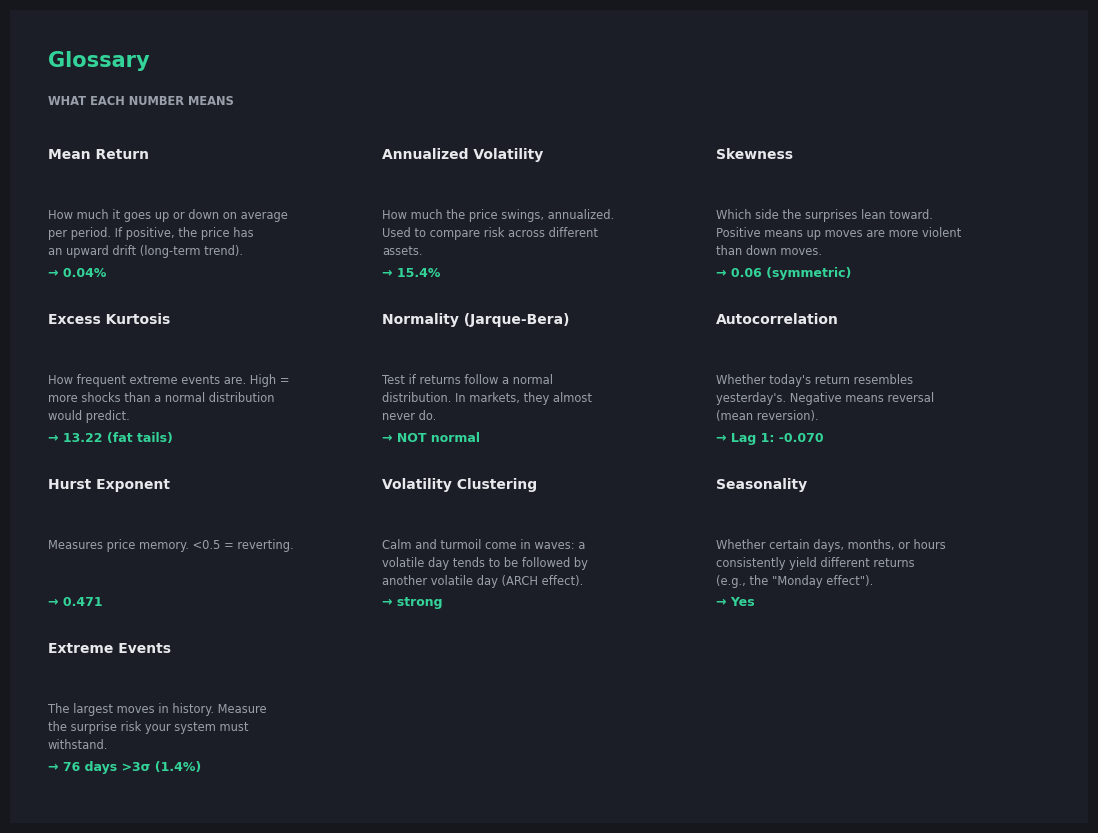




All timeframes analyzed successfully!


In [14]:
# Analyze 15min (raw data)
print("\n" + "="*70)
print("ANALYZING 15MIN TIMEFRAME")
print("="*70)
results_15min = analyze_timeframe_detailed(timeframes['15min'], '15min')

# Analyze 1H
print("\n" + "="*70)
print("ANALYZING 1H TIMEFRAME")
print("="*70)
results_1h = analyze_timeframe_detailed(timeframes['1H'], '1H')

# Analyze 4H
print("\n" + "="*70)
print("ANALYZING 4H TIMEFRAME")
print("="*70)
results_4h = analyze_timeframe_detailed(timeframes['4H'], '4H')

# Analyze 1D
print("\n" + "="*70)
print("ANALYZING 1D TIMEFRAME")
print("="*70)
results_1d = analyze_timeframe_detailed(timeframes['1D'], '1D')

print("\nAll timeframes analyzed successfully!")

# 6. Summary of Results

In [15]:
summary_df = pd.DataFrame([
    results_15min,
    results_1h,
    results_4h,
    results_1d
])

summary_df = summary_df.set_index('name')

print("\n" + "="*70)
print("SUMMARY OF KEY METRICS ACROSS TIMEFRAMES")
print("="*70)
print(summary_df[['mean_ret', 'vol_ann', 'skew', 'kurt', 'hurst', 'mr_pct', 'trend_pct']])

# Optional: Show full summary if you want all columns
print("\n" + "-"*70)
print("FULL SUMMARY (all metrics)")
print("-"*70)
print(summary_df)


SUMMARY OF KEY METRICS ACROSS TIMEFRAMES
       mean_ret    vol_ann      skew       kurt     hurst  mr_pct  trend_pct
name                                                                        
15min  0.000570  15.403398 -0.224584  83.686030  0.499952    50.0       50.0
1H     0.002236  15.403398  0.108257  49.492660  0.499915    50.0       50.0
4H     0.008389  15.403398  0.118851  33.767887  0.486430    57.5       42.5
1D     0.043152  15.403398  0.063176  13.221895  0.470715    57.5       42.5

----------------------------------------------------------------------
FULL SUMMARY (all metrics)
----------------------------------------------------------------------
       mean_ret    vol_ann      skew       kurt      normal  pct_extreme  \
name                                                                       
15min  0.000570  15.403398 -0.224584  83.686030  NOT normal     1.719780   
1H     0.002236  15.403398  0.108257  49.492660  NOT normal     1.776876   
4H     0.008389  15.40

# 7. End of Notebook

In [16]:
print("\n" + "="*70)
print("ANALYSIS COMPLETE")
print("="*70)
print("All plots and statistics have been generated.")
print("The reusable functions from eda_utils.py made this analysis concise and portable.")
print("\nSummary of key findings by timeframe:")
print("-"*50)
for idx, row in summary_df.iterrows():
    print(f"{idx}:")
    print(f"  Hurst: {row['hurst']:.3f} → {'Mean Reversion' if row['hurst'] < 0.45 else 'Trending' if row['hurst'] > 0.55 else 'Random Walk'}")
    print(f"  System bias: {row['mr_pct']:.0f}% Mean Reversion / {row['trend_pct']:.0f}% Trending")
    print(f"  Volatility (ann): {row['vol_ann']:.1f}%")
    print(f"  Extreme events (>3σ): {row['pct_extreme']:.2f}% of days")
    print("-"*50)


ANALYSIS COMPLETE
All plots and statistics have been generated.
The reusable functions from eda_utils.py made this analysis concise and portable.

Summary of key findings by timeframe:
--------------------------------------------------
15min:
  Hurst: 0.500 → Random Walk
  System bias: 50% Mean Reversion / 50% Trending
  Volatility (ann): 15.4%
  Extreme events (>3σ): 1.72% of days
--------------------------------------------------
1H:
  Hurst: 0.500 → Random Walk
  System bias: 50% Mean Reversion / 50% Trending
  Volatility (ann): 15.4%
  Extreme events (>3σ): 1.78% of days
--------------------------------------------------
4H:
  Hurst: 0.486 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 15.4%
  Extreme events (>3σ): 1.75% of days
--------------------------------------------------
1D:
  Hurst: 0.471 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 15.4%
  Extreme events (>3σ): 1.45% of days
-----------------------